# 04 — Stage D: the graph neural forecaster

**The question.** Stage C answered it for *value recovery at the same timestamp*: a linear
regression on the turbine's own history wins while that history exists, and once a turbine goes
silent only neighbour information (a graph) can carry the forecast. It also showed that
**direction-selectivity did not help** there — the direction-blind graph was best — and argued
that this is expected, because recovering a value at the same instant is a symmetric problem.

**What this notebook does.** It builds the model the proposal is about and runs it on the task
where the wake asymmetry can actually pay off: **forecasting forward in time**

$$\hat{y}_{i,t+h} = f_\theta\big(X_{i,t-11:t},\ G_t,\ E_t\big),\qquad h\in\{1,6,36\}\ \text{steps} = 10\,\text{min},\ 1\,\text{h},\ 6\,\text{h}.$$

and it is trained and evaluated with **whole turbines silenced**, which is the proposal's
headline situation. The exact design follows PLAN.md 11.4:

* the **soft cone** is the primary graph — every turbine within `R` is a candidate neighbour and
  the wind direction/angle is an *edge feature*, so attention decides whom to listen to. Hard
  cones and the reversed orientation become masks over the same edge list (exact ablations);
* a **GRU** encodes the 2-hour window per turbine, a **GATv2** processor aggregates neighbours,
  an MLP decodes the three horizons;
* a silent turbine's embedding is replaced by a learnable placeholder, and during training each
  turbine is hidden with probability `p ~ U(0, 0.5)` per sample ("trained with randomly hidden
  inputs");
* losses and metrics are computed **only on scoreable ground truth**, and predictions are
  reported in kW.

**Run modes.** The `RUN` preset below controls cost.

| mode | what it is for | rough cost on this machine (CPU) |
|---|---|---|
| `smoke` | pipeline check on a few dozen windows | under a minute per notebook |
| `quick` (default) | a first real answer, 3 seeds | ~30–60 min for all of 04–06 |
| `full` | the report run, 5 seeds, all windows | several hours on CPU; use the GPU |

Nothing below depends on the mode, only the number of windows, epochs and seeds.

## 0. Setup

In [12]:
import os, sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd()
while not (ROOT / "src" / "windgnn").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from windgnn import config as C, data as D, graphs as G, tensors as T
from windgnn import models as M, training as TR, evaluation as E, explain as X, viz as V
from windgnn.tensors import WindowSpec, GraphProvider, ForecastWindows, RandomTurbineMasker

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)

print("torch", torch.__version__, "| HIP", torch.version.hip, "| CUDA", torch.version.cuda)
print("device:", TR.resolve_device(), "| visible GPUs:", torch.cuda.device_count())
for _i in range(torch.cuda.device_count()):
    print(f"  gpu[{_i}]: {torch.cuda.get_device_name(_i)}")

torch 2.13.0+rocm7.1 | HIP 7.1.52802 | CUDA None
device: cuda | visible GPUs: 2
  gpu[0]: AMD Radeon Graphics
  gpu[1]: AMD Ryzen 5 7600 6-Core Processor


In [13]:
#: "smoke" runs in well under a minute on a slice of the data (pipeline check);
#: "quick" is the default for a first real answer; "full" is the report-quality run.
RUN = os.environ.get("WINDGNN_RUN", "full")
PRESETS = {
    "smoke": dict(train_stride=1997, val_stride=499, samples_per_epoch=32,  epochs=1,  test_stride=1499,
                  seeds=(0,), n_explain=3),
    "quick": dict(train_stride=3,   val_stride=3,   samples_per_epoch=600, epochs=30, test_stride=11,
                  seeds=(0, 1, 2), n_explain=24),
    "full":  dict(train_stride=1,   val_stride=1,   samples_per_epoch=3000, epochs=120, test_stride=1,
                  seeds=(0, 1, 2, 3, 4), n_explain=150),
}
P = PRESETS[RUN]
print(f"RUN = {RUN!r} -> {P}")

RUN = 'full' -> {'train_stride': 1, 'val_stride': 1, 'samples_per_epoch': 3000, 'epochs': 120, 'test_stride': 1, 'seeds': (0, 1, 2, 3, 4), 'n_explain': 150}


In [14]:
SPEC = WindowSpec(input_len=12, horizons=(1, 6, 36))   # 2 h of history; 10 min / 1 h / 6 h ahead
fd = T.build_feature_data()
meta = T.load_graph_meta()
ALPHA, RADIUS = float(meta["alpha_deg"]), float(meta["radius_primary_m"])
print(f"{fd.x.shape[0]:,} timestamps x {fd.n_turbines} turbines x {len(fd.names)} features")
print(f"graph configuration from Stage B: alpha = {ALPHA:.0f} deg, R = {RADIUS:.0f} m, "
      f"cone = {meta['cone_primary_deg']:.0f} deg (primary)")
print("features:", ", ".join(fd.names))

35,280 timestamps x 134 turbines x 15 features
graph configuration from Stage B: alpha = 275 deg, R = 1500 m, cone = 45 deg (primary)
features: patv, wspd, wdir_sin, wdir_cos, etmp, itmp, ndir_sin, ndir_cos, pab1, prtv, farm_sin, farm_cos, tod_sin, tod_cos, observed


## 1. Windows, splits and the masking protocol

Chronology is fixed by Stage A (days 1–171 / 172–196 / 197–245, as in Zhang et al. 2026) and a
sample only counts if **both** its input window and its target sit inside one split, so no
window can leak across a boundary. The purge is `input_len + max(h)` steps.

Two masks matter and are never mixed:

| mask | meaning | used by |
|---|---|---|
| `hidden` | the turbine reports **nothing** for the whole window (features zeroed, `observed` flag 0) | inputs |
| `valid` | the ground truth may be scored | metrics only |

The random-hiding augmentation is applied on the fly per sample, so the model sees everything
from "nobody is out" to "half the farm is out" within one epoch.

In [15]:
def window_counts(stride):
    rows = []
    for split in ("train", "val", "test"):
        t, h = T.sample_indices(fd, SPEC, split, stride=stride)
        row = {"split": split, **{f"h={hh}": int((h == hh).sum()) for hh in SPEC.horizons}}
        row["total"] = len(t)
        rows.append(row)
    return pd.DataFrame(rows)

display(window_counts(P["train_stride"]))
print(f"purge at each split boundary: {SPEC.purge} steps "
      f"({SPEC.purge * C.SAMPLE_MINUTES} min = input_len + longest horizon)")

train_t, train_h = T.sample_indices(fd, SPEC, "train", stride=P["train_stride"])
val_t, val_h = T.sample_indices(fd, SPEC, "val", stride=P["val_stride"])
test_t, test_h = T.sample_indices(fd, SPEC, "test", stride=P["test_stride"])
print(f"windows -> train {len(train_t):,}  val {len(val_t):,}  test {len(test_t):,}")

train_ds = ForecastWindows(fd, train_t, train_h, SPEC, masker=RandomTurbineMasker(0.5, seed=0))
val_ds = ForecastWindows(fd, val_t, val_h, SPEC, masker=RandomTurbineMasker(0.5, seed=1))
ref_ds = ForecastWindows(fd, test_t, test_h, SPEC)          # complete data, nobody hidden

,split,h=1,h=6,h=36,total
0,train,24612,24607,24577,73796
1,val,3588,3583,3553,10724
2,test,7044,7039,7009,21092


purge at each split boundary: 48 steps (480 min = input_len + longest horizon)
windows -> train 73,796  val 10,724  test 21,092


In [16]:
item = train_ds[0]
print({k: (tuple(v.shape) if hasattr(v, "shape") else v) for k, v in item.items()})
print(f"silent turbines in this sample: {int(item['hidden'].sum())} / {fd.n_turbines}")
print(f"scoreable targets in this sample: {int(item['y_valid'].sum())} / {fd.n_turbines}")

{'x': (12, 134, 15), 'hidden': (134,), 'y': (134,), 'y_valid': (134,), 't_end': 11, 'h': 1, 'h_index': 0}
silent turbines in this sample: 39 / 134
scoreable targets in this sample: 130 / 134


## 2. The graphs

One edge list per configuration; only the **edge mask** and the **edge attributes** change with
the wind. Each edge `i -> j` means "`j` is downwind of `i`", i.e. messages flow from upwind to
downwind, and the four edge features are `dist/R`, `along` (cosine between the pair axis and
the flow), `cross` (signed cross-flow offset) and `|angle|/90`.

The wind direction is the farm-level estimate from Stage A (robust consensus over 134 nacelles),
and `alpha = 275 deg` is Stage B's farm-axis orientation. Stage B could not settle whether the
downstream end is `alpha` or `alpha + 180`, so **the reversed orientation is a first-class
baseline here**, not an afterthought.

In [17]:
def make_graphs(alpha=ALPHA, radius=RADIUS, cone=45.0):
    return {
        "soft cone (primary)": GraphProvider(fd.loc, fd.farm_dir, fd.t_index, alpha, radius, 180.0),
        "hard cone 45":        GraphProvider(fd.loc, fd.farm_dir, fd.t_index, alpha, radius, cone),
        "reversed cone 45":    GraphProvider(fd.loc, fd.farm_dir, fd.t_index, alpha, radius, cone,
                                             reverse=True),
        "kNN k=5 (static)":    GraphProvider(fd.loc, fd.farm_dir, fd.t_index, alpha, radius,
                                             kind="knn", k=5),
    }

GRAPHS = make_graphs()
probe_t = test_t[::max(len(test_t) // 200, 1)]
rows = []
for name, g in GRAPHS.items():
    deg = g.in_degree_batch(probe_t)
    rows.append({"graph": name, "real_edges": g.meta()["n_real_edges"],
                 "mean_in_degree": deg.mean(), "isolated_share": float((deg == 0).mean())})
display(pd.DataFrame(rows).round(2))
print("Note: the soft cone keeps every pair within R, so its in-degree is the candidate set; "
      "the hard cone is the sparse directed graph the proposal describes.")

,graph,real_edges,mean_in_degree,isolated_share
0,soft cone (primary),1458,10.88,0.00
1,hard cone 45,1458,2.34,0.19
2,reversed cone 45,1458,2.34,0.19
3,kNN k=5 (static),760,5.67,0.00


Note: the soft cone keeps every pair within R, so its in-degree is the candidate set; the hard cone is the sparse directed graph the proposal describes.


## 3. The model

`WindForecaster` = per-timestep MLP → shared GRU over the window → `L` GATv2 blocks
(residual + LayerNorm) → MLP decoder with one output per horizon.

Three details that matter for the research question:

* **GATv2, not GAT.** GATv2's logit is `a^T LeakyReLU(W_l h_i + W_r h_j + W_e e_ij)`, which
  depends on the *pair*; GAT's is additive in the two node terms, so the ranking of a node's
  neighbours cannot depend on the query. If "which neighbour matters depends on the wind", GAT
  is structurally unable to express it — that is an ablation, not a preference.
* **Silent turbines** get a learnable placeholder embedding instead of their (zeroed) encoding,
  so "no data" is a distinct state rather than "a turbine reporting the average".
* **Persistence residual** (on by default): the decoder predicts a *correction* on top of the
  last observed power, so a visible turbine is not asked to relearn persistence, while a silent
  turbine starts from the climatological mean (its own history is zeroed) and must be moved by
  its neighbours.

In [18]:
MODEL_CFG = dict(graph="gatv2", d=64, n_layers=2, heads=4, edge_dim=4,
                 dropout=0.1, hidden_placeholder="learnable", residual_persistence=True)
model = M.build_model(MODEL_CFG, n_features=len(fd.names), n_horizons=len(SPEC.horizons),
                      patv_feature=fd.feature_index("patv"))
print(model.describe())

WindForecaster(graph=gatv2, layers=2, d=64, horizons=3, edge_dim=4, params=48,067)


### Verification: the batched attention layer *is* `GATv2Conv`

The layer in `windgnn.models` computes the same function as `torch_geometric.nn.GATv2Conv`
batched over graphs that share a topology (which is what lets one forward pass serve 32
farm snapshots, ~16x faster than looping over graphs). The check below loads PyG's own weights
into it and compares outputs and attention coefficients — they should agree to machine
precision, otherwise the fast path would be a different model.

In [19]:
from torch_geometric.nn import GATv2Conv
from windgnn.models import BatchedGATv2Layer

torch.manual_seed(0)
n_nodes, n_edges, din, n_heads, d_head = 40, 160, 24, 4, 8
ei = torch.stack([torch.randint(0, n_nodes, (n_edges,)), torch.randint(0, n_nodes, (n_edges,))])
ea = torch.randn(n_edges, 4)
xx = torch.randn(n_nodes, din)
for concat in (True, False):
    pyg = GATv2Conv(din, d_head, heads=n_heads, concat=concat, edge_dim=4, add_self_loops=False)
    mine = BatchedGATv2Layer(din, d_head, heads=n_heads, concat=concat, edge_dim=4)
    mine.load_state_dict(pyg.state_dict(), strict=True)
    pyg.eval(); mine.eval()
    with torch.no_grad():
        out_p, (_, alpha_p) = pyg(xx, ei, edge_attr=ea, return_attention_weights=True)
        out_m, alpha_m = mine(xx[None], ei[0], ei[1], ea[None], return_attn=True)
    print(f"concat={concat}: output max|diff| = {(out_p - out_m[0]).abs().max():.2e}, "
          f"attention max|diff| = {(alpha_p - alpha_m[0]).abs().max():.2e}")

concat=True: output max|diff| = 0.00e+00, attention max|diff| = 0.00e+00
concat=False: output max|diff| = 0.00e+00, attention max|diff| = 0.00e+00


## 4. Training

Adam, masked MSE, early stopping on the validation MAE in kW, plateau scheduler. `samples_per_epoch`
draws windows without replacement from the split, so an epoch is a fixed budget rather than a
full pass over 74k windows.

In [20]:
GRAPH_NAME = "soft cone (primary)"
graph = GRAPHS[GRAPH_NAME]
cfg = TR.TrainConfig(epochs=P["epochs"], samples_per_epoch=P["samples_per_epoch"],
                     batch_size=32, lr=5e-4, weight_decay=1e-4, patience=8,
                     seed=int(P["seeds"][0]), verbose=True, log_every=5)
t0 = time.perf_counter()
trainer = TR.fit_model(model, train_ds, val_ds, graph, cfg, fd)
print(f"\ntrained in {time.perf_counter() - t0:.1f}s | best val MAE {trainer.best_val:.1f} kW "
      f"at epoch {trainer.best_epoch}")

  epoch   0  loss 0.5576  val MAE  180.06 kW  lr 5.00e-04  *
  epoch   1  loss 0.4317  val MAE  167.79 kW  lr 5.00e-04  *
  epoch   2  loss 0.4080  val MAE  163.11 kW  lr 5.00e-04  *
  epoch   5  loss 0.3945  val MAE  163.49 kW  lr 2.50e-04
  epoch   6  loss 0.3974  val MAE  161.45 kW  lr 2.50e-04  *
  epoch   7  loss 0.3877  val MAE  158.60 kW  lr 2.50e-04  *
  epoch   9  loss 0.3934  val MAE  157.31 kW  lr 2.50e-04  *
  epoch  10  loss 0.3720  val MAE  158.99 kW  lr 2.50e-04
  epoch  15  loss 0.3744  val MAE  159.37 kW  lr 6.25e-05
  early stop at epoch 17 (best 9)

trained in 64.0s | best val MAE 157.3 kW at epoch 9


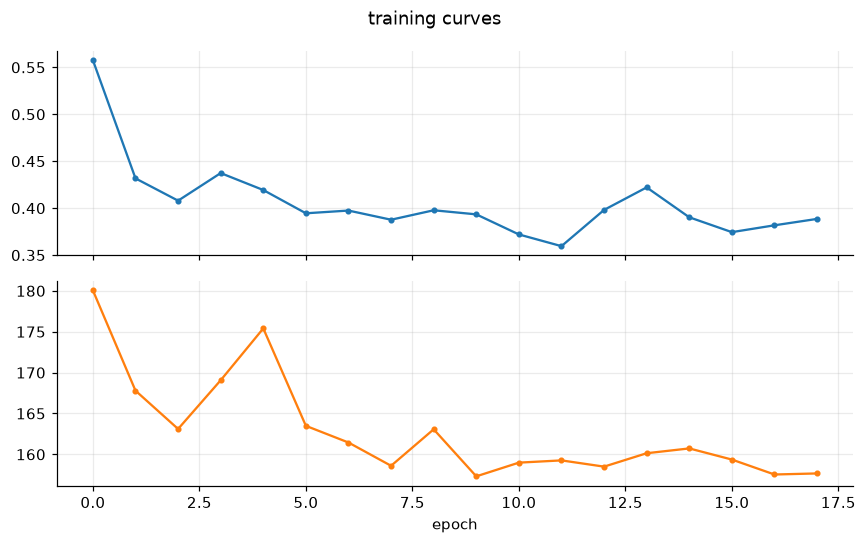

,epoch,train_loss,val_mae_kW,lr,sec
15,15,0.374448,159.365082,0.000063,56.988340
16,16,0.381728,157.537567,0.000063,60.515486
17,17,0.388542,157.667389,0.000063,64.042065


In [21]:
hist = pd.DataFrame(trainer.history)
ax = hist.plot(x="epoch", y=["train_loss", "val_mae_kW"], subplots=True, figsize=(8, 5),
               marker="o", ms=3, grid=True, legend=False, title="training curves")
V.save_figure(ax[0].figure, "stage_d_training_curves")
plt.tight_layout(); plt.show()
hist.tail(3)

## 5. Evaluation: complete data vs. turbine outages

Every scenario below uses the **same test windows** and only changes which turbines are silent,
so differences are paired. `valid` restricts the metric to the dataset's scoreable records, and
`hidden` restricts it to the turbines that reported nothing.

The scenarios are the proposal's: one turbine at a time (a sample of them), 5–50 % of the farm
at random, spatially contiguous blocks, and whole geometric columns (the worst case: everything
upwind is gone). Persistence — repeat the last observed power — is the floor every model must
beat; for a silent turbine it is computed from its last *observed* record, which is what an
operator would have.

In [22]:
scenarios = {"complete data": np.zeros((len(test_t), fd.n_turbines), dtype=bool)}
for share in (0.05, 0.1, 0.2, 0.3, 0.4, 0.5):
    scenarios[f"random {int(share*100)}%"] = T.outage_masks(
        len(test_t), fd.n_turbines, share, "random", seed=int(share * 1000))
scenarios["block 10%"] = T.outage_masks(len(test_t), fd.n_turbines, 0.10, "block", seed=7)
scenarios["whole columns"] = T.outage_masks(
    len(test_t), fd.n_turbines, 0.10, "column", seed=0,
    columns=G.detect_columns(fd.loc))

preds = {}
for name, mask in scenarios.items():
    ds = ForecastWindows(fd, test_t, test_h, SPEC, fixed_hidden=mask)
    preds[name] = TR.predict(model, ds, graph, batch_size=64)
    print(f"  {name:18s} hidden share {mask.mean():.3f}  "
          f"{preds[name].pred.shape[0]} windows")

  complete data      hidden share 0.000  21092 windows
  random 5%          hidden share 0.052  21092 windows
  random 10%         hidden share 0.097  21092 windows
  random 20%         hidden share 0.201  21092 windows
  random 30%         hidden share 0.299  21092 windows
  random 40%         hidden share 0.403  21092 windows
  random 50%         hidden share 0.500  21092 windows
  block 10%          hidden share 0.097  21092 windows
  whole columns      hidden share 0.164  21092 windows


In [23]:
overall = pd.DataFrame([{"scenario": k, **E.score(v, k)} for k, v in preds.items()])
display(overall[["scenario", "MAE", "RMSE", "R2", "bias", "n"]].round(2))

per_h = []
for k, v in preds.items():
    for h in SPEC.horizons:
        per_h.append({"scenario": k, "horizon": f"{h*10} min", **E.score(v.select(v.h == h), k)})
per_h = pd.DataFrame(per_h)
order = [f"{h*10} min" for h in SPEC.horizons]
display(per_h.pivot(index="scenario", columns="horizon", values="MAE")[order].round(1))

,scenario,MAE,RMSE,R2,bias,n
0,complete data,138.23,226.63,0.74,-18.69,2081007
1,random 5%,139.52,227.09,0.74,-17.60,2081007
2,random 10%,140.65,227.51,0.74,-16.67,2081007
3,random 20%,143.37,228.58,0.74,-14.62,2081007
4,random 30%,146.01,229.68,0.74,-12.72,2081007
5,random 40%,149.27,231.17,0.73,-10.55,2081007
6,random 50%,152.94,232.98,0.73,-8.06,2081007
7,block 10%,140.96,227.87,0.74,-16.66,2081007
8,whole columns,143.07,228.81,0.74,-13.93,2081007


horizon,10 min,60 min,360 min
scenario,,,
block 10%,61.8,127.0,234.7
complete data,57.0,124.8,233.5
random 10%,61.5,126.8,234.3
random 20%,66.5,129.0,235.2
random 30%,71.3,131.0,236.4
random 40%,76.7,133.3,238.4
random 5%,59.4,125.9,233.9
random 50%,82.2,136.0,241.2
whole columns,64.6,127.9,237.3


In [24]:
deg = E.degradation_table(preds, "complete data", subset="hidden")
deg = deg[deg.model != "complete data"].reset_index(drop=True)
display(deg[["model", "MAE", "MAE_reference", "delta_MAE", "R2", "n"]].round(3))

overall.to_csv(C.TABLES_DIR / "stage_d_scenarios.csv", index=False)
per_h.to_csv(C.TABLES_DIR / "stage_d_per_horizon.csv", index=False)
deg.to_csv(C.TABLES_DIR / "stage_d_degradation.csv", index=False)
print("saved stage_d_*.csv")

,model,MAE,MAE_reference,delta_MAE,R2,n
0,whole columns,153.087,127.137,0.204,0.698,372870
1,random 5%,162.845,138.127,0.179,0.717,108568
2,random 10%,162.944,138.241,0.179,0.715,201986
3,random 20%,163.238,138.415,0.179,0.715,419074
4,random 30%,163.502,138.467,0.181,0.714,621228
5,random 40%,164.224,138.140,0.189,0.714,838351
6,block 10%,165.203,137.484,0.202,0.712,201995
7,random 50%,166.254,138.298,0.202,0.711,1040178


saved stage_d_*.csv


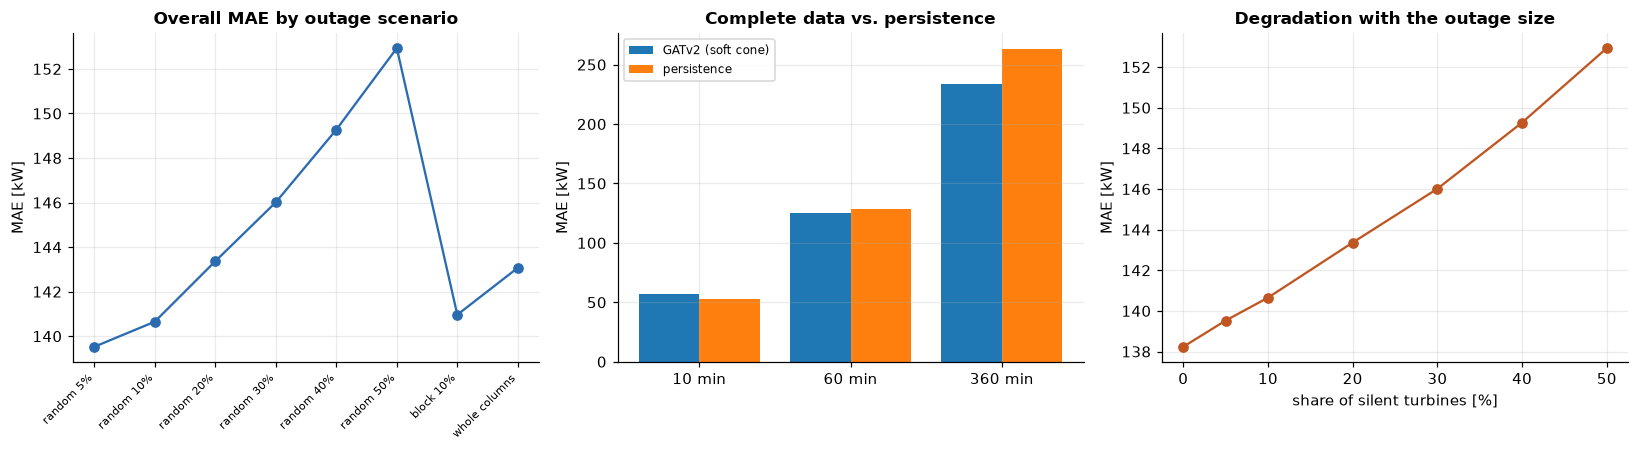

In [25]:
pers = E.persistence_predictions(preds["complete data"], fd, SPEC.input_len)
pers_h = {f"{h*10} min": E.score(pers.select(pers.h == h), "persistence")["MAE"]
          for h in SPEC.horizons}
model_h = {f"{h*10} min": E.score(preds["complete data"].select(preds["complete data"].h == h),
                                 "model")["MAE"] for h in SPEC.horizons}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
kinds = [k for k in preds if k != "complete data"]
mae = [E.score(preds[k], k)["MAE"] for k in kinds]
axes[0].plot(range(len(kinds)), mae, "o-", color="#2b6cb0")
axes[0].set_xticks(range(len(kinds))); axes[0].set_xticklabels(kinds, rotation=45, ha="right", fontsize=7)
axes[0].set_ylabel("MAE [kW]"); axes[0].set_title("Overall MAE by outage scenario")

x = np.arange(len(SPEC.horizons))
axes[1].bar(x - 0.2, [model_h[f"{h*10} min"] for h in SPEC.horizons], width=0.4, label="GATv2 (soft cone)")
axes[1].bar(x + 0.2, [pers_h[f"{h*10} min"] for h in SPEC.horizons], width=0.4, label="persistence")
axes[1].set_xticks(x); axes[1].set_xticklabels([f"{h*10} min" for h in SPEC.horizons])
axes[1].set_ylabel("MAE [kW]"); axes[1].set_title("Complete data vs. persistence"); axes[1].legend(fontsize=8)

share = [0.0] + [float(k.split()[1].strip("%")) / 100 for k in kinds if k.startswith("random")]
mae_share = [E.score(preds["complete data"], "c")["MAE"]] + [
    E.score(preds[k], k)["MAE"] for k in kinds if k.startswith("random")]
axes[2].plot(np.array(share) * 100, mae_share, "o-", color="#c05621")
axes[2].set_xlabel("share of silent turbines [%]"); axes[2].set_ylabel("MAE [kW]")
axes[2].set_title("Degradation with the outage size")
fig.tight_layout()
V.save_figure(fig, "stage_d_outage_degradation")
plt.show()

## 6. Sanity checks

Three checks that separate a working model from a plausible-looking table:

1. **does it beat persistence at every horizon?** (if not, the graph is not contributing);
2. **is the error concentrated on specific turbines?** (a few broken turbines can dominate);
3. **does hiding a turbine change anyone else's forecast?** (if nothing moves, the graph is
   effectively unused — the soft cone would be decorative).

In [26]:
cmp = pd.DataFrame([
    {"horizon": f"{h*10} min",
     "model_MAE": E.score(preds["complete data"].select(preds["complete data"].h == h), "m")["MAE"],
     "persistence_MAE": E.score(pers.select(pers.h == h), "p")["MAE"]}
    for h in SPEC.horizons])
cmp["model_better_by_%"] = (cmp.persistence_MAE - cmp.model_MAE) / cmp.persistence_MAE * 100
display(cmp.round(2))

# Per-turbine error under the 20% scenario. Absolute error: the mean of the *signed* error is a
# bias, not a MAE, and the two answer different questions, so both are reported.
p20 = preds["random 20%"]
abs_err = E.error_matrix(p20)
signed = p20.pred - p20.true
per_turb = pd.DataFrame({
    "TurbID": fd.turbine_ids,
    "MAE": np.nanmean(abs_err, axis=0),
    "bias": np.nanmean(np.where(np.isfinite(abs_err), signed, np.nan), axis=0),
    "hidden_share": p20.hidden.mean(axis=0),
}).sort_values("MAE", ascending=False)
display(per_turb.head(8).round(1))

# does hiding a turbine move a neighbour's forecast?
probe = slice(0, min(64, len(test_t)))
base = TR.predict(model, ForecastWindows(fd, test_t[probe], test_h[probe], SPEC), graph, batch_size=64)
hid = np.zeros((len(base), fd.n_turbines), dtype=bool)
hid[:, 0] = True
moved = TR.predict(model, ForecastWindows(fd, test_t[probe], test_h[probe], SPEC, fixed_hidden=hid),
                   graph, batch_size=64)
delta = np.abs(moved.pred - base.pred)[:, 1:].mean()
print(f"mean |prediction change| at other turbines when turbine 1 goes silent: {delta:.2f} kW")
print("-> a value close to 0 would mean the graph is not being used at all")

,horizon,model_MAE,persistence_MAE,model_better_by_%
0,10 min,57.03,52.97,-7.66
1,60 min,124.78,128.22,2.69
2,360 min,233.52,263.30,11.31


,TurbID,MAE,bias,hidden_share
4,5,182.5,27.600000,0.2
23,24,176.1,-54.500000,0.2
3,4,176.0,-27.500000,0.2
21,22,175.9,-49.099998,0.2
2,3,175.6,-41.900002,0.2
68,69,174.9,-50.299999,0.2
0,1,173.6,-44.700001,0.2
49,50,173.4,25.900000,0.2


mean |prediction change| at other turbines when turbine 1 goes silent: 0.29 kW
-> a value close to 0 would mean the graph is not being used at all


## 7. Save the trained model and the numbers

The checkpoint is what notebook 05 (H1/H2/H3) and notebook 06 (explanations) load, so this
notebook does not have to be re-run for every experiment.

In [27]:
name = f"stage_d_{GRAPH_NAME.split()[0]}"          # save_checkpoint appends _seed{seed}
ckpt = TR.save_checkpoint(trainer, name, cfg.seed, meta={
    "graph": GRAPH_NAME, "alpha": ALPHA, "radius": RADIUS, "cone": 180.0,
    "model_cfg": MODEL_CFG, "spec": {"input_len": SPEC.input_len, "horizons": list(SPEC.horizons)},
    "features": fd.names, "run": RUN, "best_val_kW": trainer.best_val})

summary = {"run": RUN, "checkpoint": str(ckpt.relative_to(ROOT)), "graph": GRAPH_NAME,
           "best_val_kW": trainer.best_val, "params": model.n_parameters(),
           "overall": overall.set_index("scenario")["MAE"].round(2).to_dict(),
           "persistence_by_horizon": {k: round(v, 2) for k, v in pers_h.items()},
           "model_by_horizon": {k: round(v, 2) for k, v in model_h.items()}}
(C.TABLES_DIR / "stage_d_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

{
  "run": "full",
  "checkpoint": "results/checkpoints/stage_d_soft_seed0.pt",
  "graph": "soft cone (primary)",
  "best_val_kW": 157.31216430664062,
  "params": 48067,
  "overall": {
    "complete data": 138.23,
    "random 5%": 139.52,
    "random 10%": 140.65,
    "random 20%": 143.37,
    "random 30%": 146.01,
    "random 40%": 149.27,
    "random 50%": 152.94,
    "block 10%": 140.96,
    "whole columns": 143.07
  },
  "persistence_by_horizon": {
    "10 min": 52.97,
    "60 min": 128.22,
    "360 min": 263.3
  },
  "model_by_horizon": {
    "10 min": 57.03,
    "60 min": 124.78,
    "360 min": 233.52
  }
}


## 8. What this establishes, and what it does not

* The pipeline reproduces the proposal's setting end to end: a turbine that reports **nothing**
  is forecast from its neighbours, at three horizons, with metrics on scoreable ground truth.
* The numbers above are the **complete-data vs. outage** comparison for one graph configuration.
  They are a sanity check, not the result: H1 needs the *same* comparison across several graphs
  and seeds (notebook 05), and H2/H3 need the exposure structure (who is upwind of whom) rather
  than the farm average.
* Two caveats to carry forward. (i) Stage B could not fix which end of the farm axis is
  downstream, so `alpha + 180` must stay in the comparison. (ii) A soft cone gives every turbine
  a dozen candidate neighbours; a directional benefit must therefore show up as *attention*
  choosing among them, which is exactly what notebook 06 inspects.